# Project 4, APS1070 Fall 2024
#### **Linear Regression -  14 points**
**Deadline: Nov 29th, 23:00**

**Academic Integrity**

This project is individual - it is to be completed on your own. If you have questions, please post your query in the APS1070 Piazza Q&A forums (the answer might be useful to others!).

Do not share your code with others, or post your work online. Do not submit code that you have not written yourself without proper acknowledgment of the source, including generated code (please refer to the course syllabus). Students suspected of plagiarism on a project, midterm or exam will be referred to the department for formal discipline for breaches of the Student Code of Conduct.

Please fill out the following:


*   Your **name**: Tiffany Costas
*   Your **student number**: 1005854844

### How to submit **(HTML + IPYNB)**

1. Download your notebook: `File -> Download .ipynb`

2. Click on the Files icon on the far left menu of Colab

3. Select & upload your `.ipynb` file you just downloaded, and then obtain its path (right click) (you might need to hit the Refresh button before your file shows up)


4. execute the following in a Colab cell:
```
%%shell
jupyter nbconvert --to html /PATH/TO/YOUR/NOTEBOOKFILE.ipynb
```

5. An HTML version of your notebook will appear in the files, so you can download it.

6. Submit **both** <font color='red'>`HTML` and `IPYNB`</font>  files for this notebook on Quercus for grading.


Ref: https://stackoverflow.com/a/64487858

## Part 1 - Getting Started [2 marks]

In this project, we are going to design a mathematical model that predicts electrical grid stability, as described in the paper below:

*Schäfer, Benjamin, et al. 'Taming instabilities in power grid networks by decentralized control.' The European Physical Journal Special Topics 225.3 (2016): 569-582.*


For this purpose, we are using the [Electrical Grid Stability](https://archive.ics.uci.edu/dataset/471/electrical+grid+stability+simulated+data) dataset which includes 10000 instances with 12 features describing the power grid's status. The goal is to unravel patterns and predict the `stab` column, which is a characteristic of the grid that represents its stability. Note that you can ignore the last column named `stabf` since this is a binary indicator showing whether the stability is above a certain threshold.

In [1]:
import pandas as pd
df = pd.read_csv(
    filepath_or_buffer="https://raw.githubusercontent.com/Sabaae/Dataset/main/electrical_grid_stability_simulated_data.csv",
    skipinitialspace=True
)

Here are the steps to complete this portion:

1. Print the dataframe.
2. Prepare your dataset as follows: **[1.5]**
*   Using `train_test_split` from Sklearn, split the dataset into training and validation sets ($80\%$ training, $20\%$ validation). When splitting, set `random_state=111`. **[0.5]**
*   Standardize the data **manually** according to the same method as `StandardScaler` from sklearn, but you may not directly use `StandardScaler'. **[0.5]**
*   Insert a first column of all $1$s in both the training and validation data sets.**[0.5]**
3. Explain why we should not insert the column of $1$s prior to standardization. **[0.5]**

**Answer**

---
We should not insert the column of 1s prior to standardization because it would incorrectly standardize the bias term, improperly treating it as a feature. The column of 1s represents the intercept in our linear regression model. By standardizing it would force it to have a mean of 0 and a standard deviation of 1, like other features, effectively removing the intercept. The bias term acts as a baseline adjustment in the model and should remain unaffected by standardization to allow the model to accurately fit the data.

In [2]:
### YOUR CODE HERE ###
#step 1: print dataframe
df

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.930406,9.487627,2.376523,6.187797,3.343416,-0.658054,-1.449106,-1.236256,0.601709,0.779642,0.813512,0.608385,0.023892,unstable
9996,3.392299,1.274827,2.954947,6.894759,4.349512,-1.663661,-0.952437,-1.733414,0.502079,0.567242,0.285880,0.366120,-0.025803,stable
9997,2.364034,2.842030,8.776391,1.008906,4.299976,-1.380719,-0.943884,-1.975373,0.487838,0.986505,0.149286,0.145984,-0.031810,stable
9998,9.631511,3.994398,2.757071,7.821347,2.514755,-0.966330,-0.649915,-0.898510,0.365246,0.587558,0.889118,0.818391,0.037789,unstable


In [3]:
#step 2: prepare dataset
#split data into training and validation sets:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['stab','stabf']).values
y = df['stab'].values
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=111)

In [4]:
#manually standardize the data using same method as StandardScaler (uses z score)
#z score uses the mean and std of the training samples
import numpy as np
mu, sigma = np.mean(X_train, axis = 0), np.std(X_train, axis = 0)
X_train_std = (X_train - mu)/sigma
X_val_std = (X_val - mu)/sigma

In [5]:
#insert first column of all 1s (bias term) in train/val datasets
X_train_std = np.hstack((np.ones((X_train_std.shape[0], 1)), X_train_std))
X_val_std = np.hstack((np.ones((X_val_std.shape[0], 1)), X_val_std))
print(X_train_std.shape, X_val_std.shape, y_train.shape, y_val.shape)

(8000, 13) (2000, 13) (8000,) (2000,)


## Part 2 - Linear Regression Using Direct Solution [1 marks]

Implement the direct solution of the linear regression problem on the training set. **[0.5]**

**Note: You should use scipy.linalg.inv to perform the inversion, as numpy.linalg.inv may cause an error.**

Report the root-mean-square error (RMSE) for both the training and validation sets. **[0.5]**

You may use `root_mean_squared_error` from Sklearn for computing the RMSE.

In [6]:
### YOUR CODE HERE ###
from sklearn.metrics import mean_squared_error
import scipy.linalg
import matplotlib.pyplot as plt

#Code derived from APS1070_Tutorial_Linear_Regression.ipynb
W = np.dot(scipy.linalg.inv(np.dot(X_train_std.T, X_train_std)), np.dot(X_train_std.T, y_train)) #finds weights

y_train_pred = np.dot(X_train_std, W) #prediction on training set
y_val_pred = np.dot(X_val_std, W) #prediction on validation set

RMSE_train = np.sqrt(mean_squared_error(y_train, y_train_pred)) #RMSE on training set
RMSE_val = np.sqrt(mean_squared_error(y_val, y_val_pred)) #RMSE on validation set

print('RMSE on training set: ', RMSE_train)
print('RMSE on validation set: ', RMSE_val)

RMSE on training set:  0.022010790926537325
RMSE on validation set:  0.021976140989718396


## Part 3 - Full Batch Gradient Descent [4 marks]

We will now implement a "full batch" gradient descent algorithm and record the training time for our model. Recall that the full batch gradient descent is,
 $$w_t = w_{t-1} - \alpha~g_t$$ where $\alpha$ is the learning rate and $g_t$ is your gradient, computed on the entire data.

Here are the steps for this part:

* Implement gradient descent for linear regression using a fixed learning rate of $\alpha= 0.01$, and iterate until your model's **validation** RMSE converges.

  We consider the gradient descent as having converged when RMSE on the validation set using gradient descent satisfies:

  $$ RMSE_\text{GD} \leq 1.0005 \times RMSE_\text{Direct Solution}$$

  where $RMSE_\text{Direct Solution}$ is the RMSE on the validation set using the direct solution that you calculated in the previous part.

  We refer to the quantity $RMSE_\text{Direct Solution}\times 1.0005$ as the convergence threshold (CT).
  Be sure to compute the gradients yourself! Take a look at the code provided in the tutorial. **[1]**

*  Record the training time (from the first iteration until convergence) using the `time.time()` function. **[0.5]**

* Plot the training RMSE and the validation RMSE vs. epoch on the same figure.  **[1]**

* Comment on overfitting/underfitting by observing the training and validation RMSE **[1]**

    **Hint**: Initialize your weights with small random numbers (<$0.00001$) & please set **np.random.seed(1001)**

* Explain the difference between epoch and iteration in the Gradient descent algorithm (SGD/mini-batch)? **[0.5]**

**Answer**

---
An epoch represents each instance the model sees and learns the whole dataset whereas an iteration is each instance where the weights are updated. In SGD, where batch size is 1, the number of iterations in one epoch is equal to the total number of training samples. For batch sizes greater than 1 (but not equal to the entire dataset - this would be full batch), the number of iterations per epoch is reduces and is equal to the total number of training samples divided by the batch size.

For example if there were 1000 samples in a dataset:
- SGD would have 1000 iterations per epoch
- mini batch with a batch size of 10 would have 1000/10 = 100 iterations per epoch

0.021987129060213252
Epoch:  0 Validation RMSE:  0.03975503157244324
Epoch:  1 Validation RMSE:  0.03947079018662425
Epoch:  2 Validation RMSE:  0.039190314846399316
Epoch:  3 Validation RMSE:  0.038913568271174426
Epoch:  4 Validation RMSE:  0.038640513443248405
Epoch:  5 Validation RMSE:  0.0383711136037713
Epoch:  6 Validation RMSE:  0.03810533224880461
Epoch:  7 Validation RMSE:  0.037843133125484325
Epoch:  8 Validation RMSE:  0.037584480228287885
Epoch:  9 Validation RMSE:  0.037329337795405926
Epoch:  10 Validation RMSE:  0.03707767030521974
Epoch:  11 Validation RMSE:  0.03682944247288523
Epoch:  12 Validation RMSE:  0.03658461924702414
Epoch:  13 Validation RMSE:  0.036343165806523234
Epoch:  14 Validation RMSE:  0.03610504755744188
Epoch:  15 Validation RMSE:  0.035870230130028706
Epoch:  16 Validation RMSE:  0.03563867937584764
Epoch:  17 Validation RMSE:  0.0354103613650136
Epoch:  18 Validation RMSE:  0.03518524238353814
Epoch:  19 Validation RMSE:  0.034963288930785125
Ep

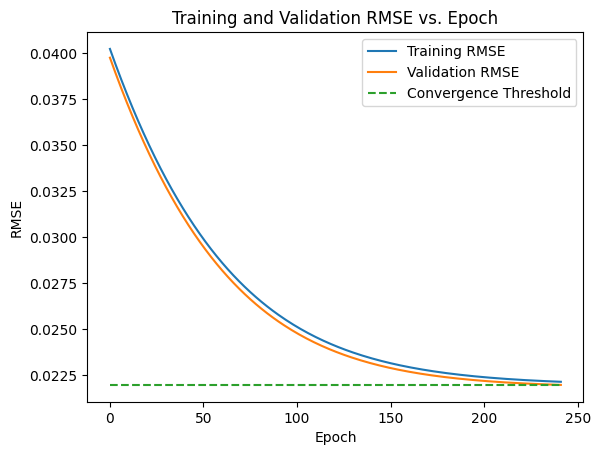

--- Total Training Time: 1.1569604873657227 (s) ---


In [56]:
import time
start_time = time.time() ## Records current time
np.random.seed(1001)

## GD Script -- Sample code in tutorial! ##
lr = 0.01
train_rmse = []
val_rmse = []
ct = RMSE_val*1.0005 #convergence threshold
w = np.random.uniform(low=-0.00001, high=0.00001, size=(X_train_std.shape[1])) #initialize weights with small random numbers
print (ct)
for epoch in range(0, 3000):
  y_train_pred = np.dot(X_train_std, w.T).reshape(-1,1)
  y_val_pred = np.dot(X_val_std, w.T).reshape(-1,1)
  t = y_train_pred - y_train.reshape(-1,1) #error between predictions and true values
  train_rmse.append(np.sqrt(mean_squared_error(y_train, y_train_pred)))
  val_rmse.append(np.sqrt(mean_squared_error(y_val, y_val_pred)))
  gradient = (1/len(y_train) * np.dot(X_train_std.T, t)).reshape(1,-1)
  w = w - lr * gradient #weight update

  print("Epoch: ", epoch, "Validation RMSE: ", val_rmse[epoch])
  #check convergence is val_rmse[epoch] <= 1.005*rmse_val
  if val_rmse[epoch] <= ct:
    break
plt.plot(train_rmse, label='Training RMSE')
plt.plot(val_rmse, label='Validation RMSE')
plt.plot([ct]*len(train_rmse), linestyle="dashed", label="Convergence Threshold")
plt.title('Training and Validation RMSE vs. Epoch')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.show()
print("--- Total Training Time: %s (s) ---" % (time.time() - start_time))

## Part 4 - Mini-batch and Stochastic Gradient Descent [4 marks]

Write a function that performs mini-batch gradient descent until the convergence threshold (CT) is reached. **[1]**

The inputs of that function are:
  * Input data (training/validation), Batch size, Learning Rate, Convergence Threshold (CT)

Your function will return the following arrays:
 * The final weights after training.
 * The training RMSE at each epoch.
 * The validation RMSE at each epoch.
 * An array that has the elapsed time from the start of the training process to the end of each epoch (e.g., if each epoch takes exactly 2 seconds, the array would look like: [2 4 6 8 ...]).

Notes:
* use **np.random.seed(1001)** before setting the initial (random) weights

  ```
  def mini_batch_gd(YOUR_INPUTS):
    np.random.seed(1001)

    ### YOUR CODE HERE ###
    
    return YOUR_OUTPUTS
  ```

* For certain batch sizes, GD might not converge to a solution. For that reason, you need to check the RMSE of the validation/training set at each epoch, and if it's getting larger and larger, you should stop the training for that case (the design is up to you!).
* CT will help you to know when your model is converged.
* **Important: after each epoch, you need to shuffle the entire training set.** This ensures that new mini-batches are selected for every epoch. Hint: use `np.random.permutation`.

Let's now use the function to investigate the effect of batch size on convergence. When the batch size is 1, we call that stochastic gradient descent. When the batch size equals the # of training data, it is full-batch (i.e., all data points are used at every iteration). Anywhere in between is mini-batch (we use some of the data).
  * Sweep different values for the mini-batch size (at least 5 values that **converge**), each time using a learning rate of $\alpha= 0.01$. **Hint: Try batch sizes that are powers of two (e.g., 2,4,8,16,...).** These batch sizes fit better on the hardware and may achieve higher performance.  **[0.5]**

Provide the following $3$ plots:
  1.  Plot training and validation RMSE vs. **epoch** for all the **converging** batch sizes (some batch sizes might not converge) in a figure. The X-axis is Epoch # and the Y-axis is RMSE. **[0.5]**
  2. Plot training and validation RMSE vs. **time** for all the **converging** batch sizes in a figure. The X-axis is Time, and the Y-axis is RMSE. **[0.5]**
  3. Plot Total training time (y-axis) vs. Batch size (x-axis). **[0.5]**

Describe your findings, including the main takeaways from each of your plots. **[1]**

In [65]:
### YOUR CODE HERE ###

def mini_batch_gd(X_train, y_train, X_val, y_val, batch_size, lr, ct):
  np.random.seed(1001)
  start_time = time.time()

  w = np.random.uniform(low=-0.00001, high=0.00001, size=(X_train.shape[1])) #initialize weights

  train_rmse = []
  val_rmse = []
  epoch_times = []

  #tracking variables for early stopping
  prev_val_rmse = float('inf')
  patience = 3 #limit for when to stop if model is no longer improving
  counter = 0

  for epoch in range(0, 3000):
    if epoch != 0: #shuffle
      row_indices = np.random.permutation(len(X_train)) #randomly shuffle training data by row indices
      X_train_shuffle = X_train[row_indices]
      y_train_shuffle = y_train[row_indices]
    else: #on first epoch keep original order of data
      X_train_shuffle = X_train
      y_train_shuffle = y_train
    for i in range(0, len(X_train), batch_size):
      X_batch = X_train_shuffle[i:i+batch_size] #obtain mini batches
      y_batch = y_train_shuffle[i:i+batch_size]

      y_train_mini_pred = np.dot(X_batch, w.T).reshape(-1,1)
      t = y_train_mini_pred - y_batch.reshape(-1,1) #error between predictions and true values

      gradient = (1/len(X_batch) * np.dot(X_batch.T, t)).reshape(1,-1) #compute gradient
      w = w - lr * gradient #weight update

    #after 1 epoch (pass through all mini batches) - compute time, the train and val RMSE
    epoch_time = time.time() - start_time
    epoch_times.append(epoch_time)

    y_train_pred = np.dot(X_train, w.T).reshape(-1,1)
    y_val_pred = np.dot(X_val, w.T).reshape(-1,1)

    train_rmse_epoch = np.sqrt(mean_squared_error(y_train, y_train_pred))
    val_rmse_epoch = np.sqrt(mean_squared_error(y_val, y_val_pred))
    train_rmse.append(train_rmse_epoch)
    val_rmse.append(val_rmse_epoch)

    #print status
    print("Epoch: ", epoch, " Train RMSE: ", train_rmse_epoch, " Validation RMSE: ", val_rmse_epoch)

    #check if RMSE is diverging (early stopping)
    if val_rmse_epoch > prev_val_rmse:
      counter += 1
    else:
      counter = 0
    prev_val_rmse = val_rmse_epoch

    #early stopping (if at 3 consecutive epochs the val rmse is still increasing) or reached 3000 epochs
    if counter == 3 or epoch == 2999:
      print("Early stopping at epoch: ", epoch, " batch size: ", batch_size)
      break

    #converging statement
    if val_rmse_epoch <= ct:
      print("Converged at epoch: ", epoch, " batch size: ", batch_size)
      break



  return w, train_rmse, val_rmse, epoch_times


In [66]:
#plot training and validation RMSE vs epoch for converging batch sizes
batch_sizes = [2, 4, 8, 16, 32, 64, 128]
lr = 0.01
ct = RMSE_val*1.0005
results = {}
for batch_size in batch_sizes:
  print("Batch size: ", batch_size)
  w, train_rmse, val_rmse, epoch_times = mini_batch_gd(X_train_std, y_train, X_val_std, y_val, batch_size, lr, ct)
  results[batch_size] = (train_rmse, val_rmse, epoch_times)


Batch size:  2
Epoch:  0  Train RMSE:  0.022280134206514538  Validation RMSE:  0.02215173269215032
Epoch:  1  Train RMSE:  0.022331181553875454  Validation RMSE:  0.022228272725010084
Epoch:  2  Train RMSE:  0.02231904369825272  Validation RMSE:  0.022183001689231544
Epoch:  3  Train RMSE:  0.022372321225070844  Validation RMSE:  0.02231625835462874
Epoch:  4  Train RMSE:  0.02221757355488057  Validation RMSE:  0.022221273897742047
Epoch:  5  Train RMSE:  0.02217075765498268  Validation RMSE:  0.022071828439677154
Epoch:  6  Train RMSE:  0.022410739279679775  Validation RMSE:  0.02241331774402702
Epoch:  7  Train RMSE:  0.02217712672432268  Validation RMSE:  0.022255292556519576
Epoch:  8  Train RMSE:  0.02253571466581351  Validation RMSE:  0.022372254376917828
Epoch:  9  Train RMSE:  0.022302031167593134  Validation RMSE:  0.02216057891246737
Epoch:  10  Train RMSE:  0.022401636356937576  Validation RMSE:  0.022198355586059256
Epoch:  11  Train RMSE:  0.022104041966975945  Validation 

<ipython-input-59-fbb4cf9e4199>:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colours = cm.get_cmap('tab10', len(results))  #get a colourmap to make sure no colours repeat


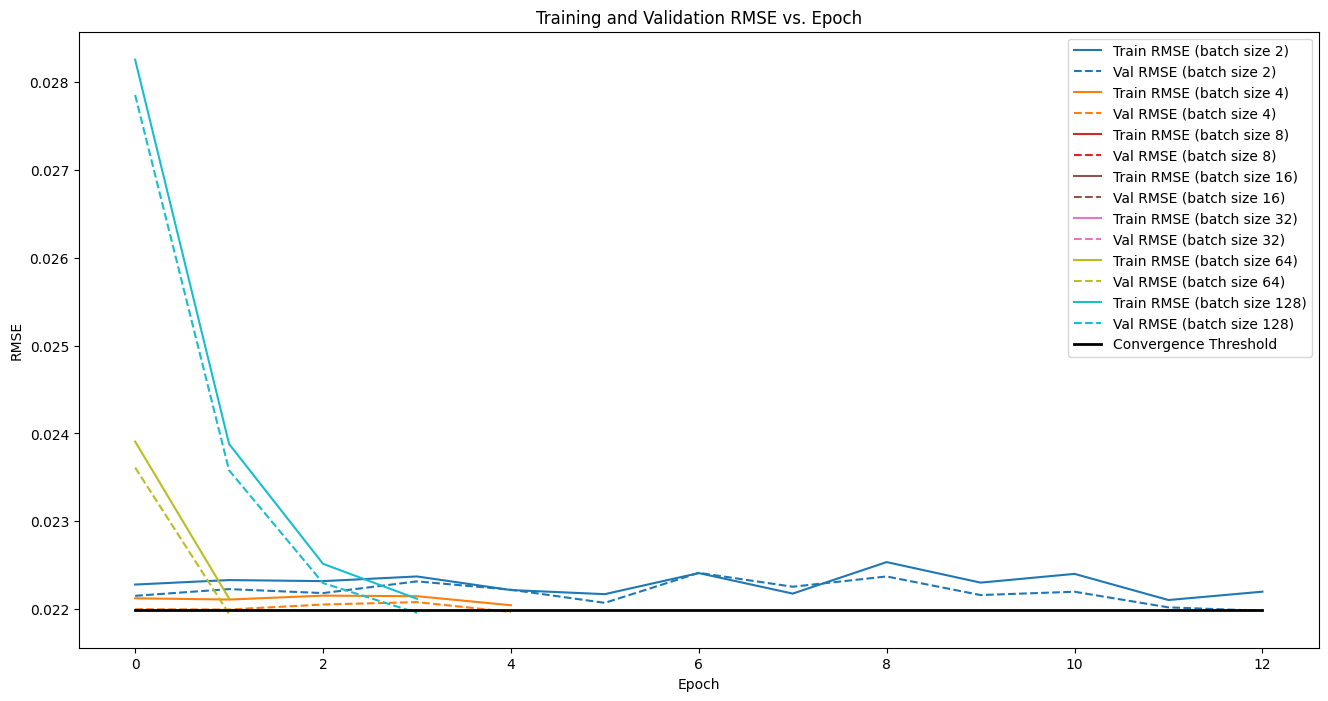

In [59]:
#plot 1: Train/Val RMSE vs Epoch for converging epochs
import matplotlib.cm as cm
plt.figure(figsize=(16, 8))

colours = cm.get_cmap('tab10', len(results))  #get a colourmap to make sure no colours repeat

for idx, (batch_size, (train_rmse, val_rmse, epoch_times)) in enumerate(results.items()):
    colour = colours(idx)  #get unique colour for each batch size
    plt.plot(train_rmse, label=f'Train RMSE (batch size {batch_size})', color=colour)
    plt.plot(val_rmse, linestyle='dashed', label=f'Val RMSE (batch size {batch_size})', color=colour)
plt.plot([ct]*13, linewidth=2, color='black', label="Convergence Threshold")
plt.title('Training and Validation RMSE vs. Epoch')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.show()

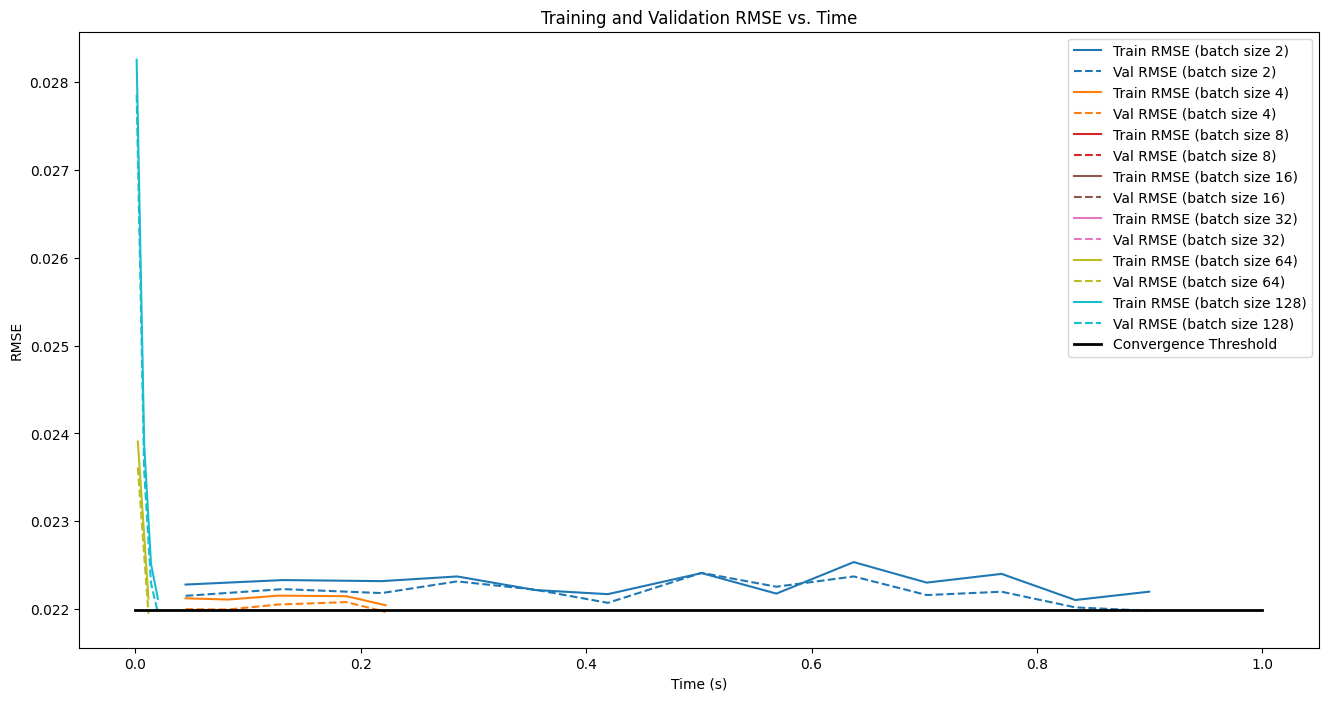

In [60]:
#plot 2: Train/Val RMSE vs Time for converging epochs
plt.figure(figsize=(16, 8))
for idx, (batch_size, (train_rmse, val_rmse, epoch_times)) in enumerate(results.items()):
    colour = colours(idx)  # Get a unique color for each batch size
    plt.plot(epoch_times, train_rmse, label=f'Train RMSE (batch size {batch_size})', color=colour)
    plt.plot(epoch_times, val_rmse, linestyle='dashed', label=f'Val RMSE (batch size {batch_size})', color=colour)
plt.plot([ct]*2, linewidth=2, color='black', label="Convergence Threshold")
plt.title('Training and Validation RMSE vs. Time')
plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('RMSE')
plt.show()

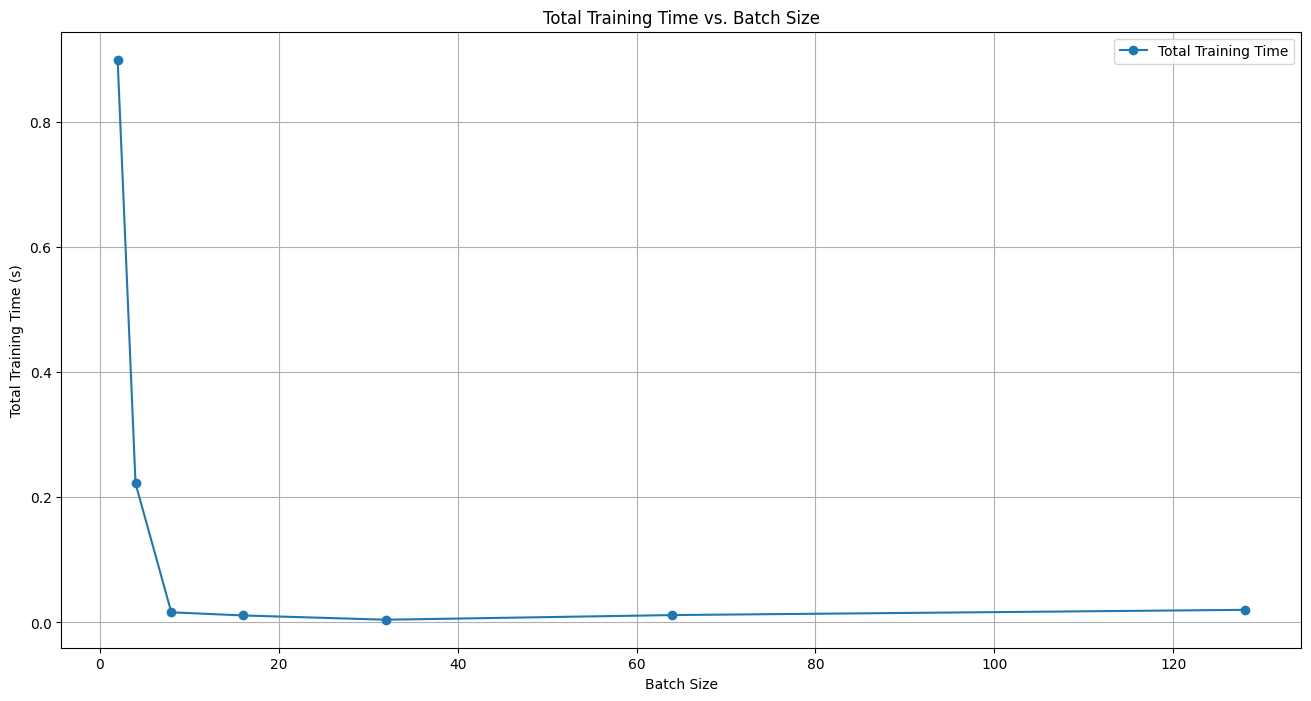

In [61]:
#plot 3: Batch Size vs Total Training Time
plt.figure(figsize=(16, 8))
total_time = [epoch_times[-1] for batch_size, (train_rmse, val_rmse, epoch_times) in results.items()] #total time is the last epoch (since we are recording the cumulative time)
plt.plot(results.keys(), total_time, label='Total Training Time', marker = 'o')
plt.title('Total Training Time vs. Batch Size')
plt.xlabel('Batch Size')
plt.ylabel('Total Training Time (s)')
plt.grid(True)
plt.legend()

**Findings & Main Takeaways**

---
Based on the graphs, the main takeaways are that as the batch size increases, the number of epochs it takes for the model to converge decreases and the time it takes to converge decreases as well. The optimal batch sizes that results in the smallest total training time is 32, as the third graph reaches a minimum time at that point

For plot 1 (Train/Val RMSE vs Epochs), for batch sizes 2 and 4, more oscillation is exhibited during the the later epochs which shows that its more sensitive to noise in the data. Batch sizes 8, 16, and 32 are not even plotted on the graph as the converged instantly after 1 epoch. Batch sizes of 64 and 128 result in smoother convergence curves, as less weight updates lead to less variance between epochs. We can also note that larger batch sizes begin with a higher RMSE error in contrast to the smaller ones, which begin with a RMSE value much closer to the convergence threshold. While none of the batch sizes failed to converge - likely due to the early stopping with patience design used (which was if it could not converge after 3 consecutive Val RMSE increase or if it reached 3000 epochs), we can see that the smaller batch sizes may benefit from a smaller learning rate. The Train/Val RMSE also show no signs of over/underfitting as they follow a similar trajectory indicating that its consistently able to generalize the data.

For plot 2 (Train/Val RMSE vs Time), a similar pattern is shown to plot 1 with respect to the shapes of the curves. While batch sizes 2 and 4 showed a much slower weight update per epoch, batch sizes 64 and 128 were rapid. This makes sense since large batch sizes perform fewer updates as they process more data per batch, making them computationally more efficienct. Even though the smaller batch sizes show quicker initial improvements to RMSE per epoch, they are less time efficient overall. Since all batch sizes converge to similar final RMSE levels, this shows that batch size has a bigger impact on training time rather than the quality of the model.

For plot 3 (batch size vs total training time), there is a noticeable inverse relationship between total training time and batch size as noted earlier. We notice the most significant drop in time efficiency when moving from a very small batch size (2) to a slightly larger one (16/32). It can also be observed that the benefits of larger batch sizes (such as 64 or 128) actually don't show much improvement compared to more mid-size ones (32 or 64), as the training times are nearly identical. The near flat curve at around 16 epochs onwards also suggests that an optimal point has been reached. Based on the plot, that appears to be at 32 epochs. Similar to plot 2, we find that smaller batch sizes are computationally more expensive, and therefore larger ones should be considered if computational time is a constraint.


## Part 5 - Gradient Descent Learning Rate [3 marks]
Use the function that you designed in Part 4 to investigate the effect of learning rate on convergence.

1. Pick 3 batch sizes that do not converge with a learning rate of $\alpha= 0.01$ (last part) and try to find a learning rate that results in convergence for each batch size. Report your findings in a table. Mention batch size, learning rate, and training and validation RMSE. **[1]**
**Note:** Since all batch sizes converged, I will select 2, 4, and 8. Batch size of 2 showed a flat convergence plot - indicating that it is not learning effectively because the learning rate is too small, which is also the same for 4. In this case, a larger learning rate may work better. For a batch size of 8, the model instantly converged after 1 epoch, so adapting the learning size to something smaller so that it can converge a bit slower may also improve the model. This will be explored in this part
2. Select the best batch size based on Part 4's fastest convergence time and sweep the learning rate (at least 10 values, all should converge) while applying Mini-batch GD.
  
  * Plot the training and validation RMSE vs. **epoch** (x-axis) for all the learning rates that you tried in a figure. **[0.5]**
  * Plot the training and validation RMSE vs. **time** (x-axis) for all the learning rates that you tried in a figure. **[0.5]**
  * Describe your findings, including the main takeaways from each of your plots. **[1]**

In [95]:
### YOUR CODE HERE ###
lrs = np.linspace(1e-5, 1e-2, 10)
batches = [2, 4, 8]
output = {}
for learning_rate in lrs:
  for batch in batches:
    print("Learning Rate: ", learning_rate, " Batch Size: ", batch)
    w, train_rmse, val_rmse, epoch_times = mini_batch_gd(X_train_std, y_train, X_val_std, y_val, batch, learning_rate, ct)

    #check if it converged:
    if val_rmse[-1] <= ct:
      output[(learning_rate, batch)] = (train_rmse, val_rmse, epoch_times, 'Yes')
    else:
      output[(learning_rate, batch)] = (train_rmse, val_rmse, epoch_times, 'No')


Learning Rate:  1e-05  Batch Size:  2
Epoch:  0  Train RMSE:  0.039120533027822556  Validation RMSE:  0.038645947275585034
Epoch:  1  Train RMSE:  0.03806716553840865  Validation RMSE:  0.03759479025171292
Epoch:  2  Train RMSE:  0.037069054296667014  Validation RMSE:  0.03659922416010968
Epoch:  3  Train RMSE:  0.03612394950719564  Validation RMSE:  0.03565711508691169
Epoch:  4  Train RMSE:  0.035229733000564374  Validation RMSE:  0.03476624273807684
Epoch:  5  Train RMSE:  0.03438416059600549  Validation RMSE:  0.03392439359621439
Epoch:  6  Train RMSE:  0.03358554977224916  Validation RMSE:  0.033129835437695244
Epoch:  7  Train RMSE:  0.03283164658541863  Validation RMSE:  0.03238031451883074
Epoch:  8  Train RMSE:  0.03212053105219893  Validation RMSE:  0.03167385639388861
Epoch:  9  Train RMSE:  0.031450253535227055  Validation RMSE:  0.031008587499954814
Epoch:  10  Train RMSE:  0.030819212571730068  Validation RMSE:  0.030382792392001975
Epoch:  11  Train RMSE:  0.030225529120

In [96]:
#create summary table
output_list = []
for (learning_rate, batch), (train_rmse, val_rmse, epoch_times, converged) in output.items():
  output_list.append({
      'Learning Rate': learning_rate,
      'Batch Size': batch,
      'Train RMSE': train_rmse[-1],
      'Val RMSE': val_rmse[-1],
      'Converged': converged
  })

df = pd.DataFrame(output_list)
df


,Learning Rate,Batch Size,Train RMSE,Val RMSE,Converged
0,0.00001,2,0.022150,0.021981,Yes
1,0.00001,4,0.022150,0.021981,Yes
2,0.00001,8,0.022154,0.021984,Yes
3,0.00112,2,0.021985,0.021874,Yes
4,0.00112,4,0.021968,0.021832,Yes
5,0.00112,8,0.021993,0.021852,Yes
6,0.00223,2,0.022025,0.021915,Yes
7,0.00223,4,0.021985,0.021874,Yes
8,0.00223,8,0.021968,0.021832,Yes
9,0.00334,2,0.022065,0.021948,Yes


In [97]:
#sort results df to only output best Train/Val RMSE for each batch size
df = df.sort_values(by=['Batch Size', 'Val RMSE'])
df = df.drop_duplicates(subset=['Batch Size'])
df

,Learning Rate,Batch Size,Train RMSE,Val RMSE,Converged
3,0.00112,2,0.021985,0.021874,Yes
4,0.00112,4,0.021968,0.021832,Yes
8,0.00223,8,0.021968,0.021832,Yes


**Comments on 1**

---
For a batch size of 2, 4 and 8, a learning rate of 0.001 and 0.002 respectively resulted in convergences with the best val RMSE of around 0.0218. This corroborates with my note from earlier (where I explained why I selected these 3 batch sizes even though they converged), as the initial learning rate of 0.01 was too large. The smaller learning rate allows for more stable convergence. For comparison, these were the resulting Val RMSE from part 4 for batches 2, 4 and 8: 0.02198, 0.02196, and 0.02192. I also noticed that 2 of the learning rates failed in the first table - batch size of 2 with a learning rate of 0.00556 and 0.00667. Using larger learning rates with small batch sizes might introduce more randomness to the model, which is likely why the model began to diverge and reached the early stopping constraint - leading to an inability to converge.

In [91]:
#Extract fastest convergence time from part 4
batch_times = {}
for batch, (train_rmse, val_rmse, epoch_times) in results.items():
  batch_times[batch] = epoch_times[-1] #total convergence time for batch size

best_batch = min(batch_times, key=batch_times.get)
print("Best batch size: ", best_batch)

#sweep learning rate
lrs2 = np.linspace(5e-5, 5e-4, 10) #smaller learning rate tend to work better for larger batch size
lr_results = {}
for lr in lrs2:
  print("Learning Rate: ", lr)
  w, train_rmse, val_rmse, epoch_times = mini_batch_gd(X_train_std, y_train, X_val_std, y_val, best_batch, lr, ct)
  if val_rmse[-1] <= ct:
    lr_results[lr] = (train_rmse, val_rmse, epoch_times)


Best batch size:  32
Learning Rate:  5e-05
Epoch:  0  Train RMSE:  0.03987796794940622  Validation RMSE:  0.039402086901385594
Epoch:  1  Train RMSE:  0.03953027907685304  Validation RMSE:  0.039054955278395115
Epoch:  2  Train RMSE:  0.039188292193130976  Validation RMSE:  0.03871355941460874
Epoch:  3  Train RMSE:  0.038851931988568275  Validation RMSE:  0.03837783633808662
Epoch:  4  Train RMSE:  0.03852113196335439  Validation RMSE:  0.038047710720706306
Epoch:  5  Train RMSE:  0.03819580672442441  Validation RMSE:  0.0377231001817232
Epoch:  6  Train RMSE:  0.03787592486399667  Validation RMSE:  0.03740397009445262
Epoch:  7  Train RMSE:  0.037561391073348556  Validation RMSE:  0.037090226470443674
Epoch:  8  Train RMSE:  0.03725213963580703  Validation RMSE:  0.03678179931927898
Epoch:  9  Train RMSE:  0.03694809690045063  Validation RMSE:  0.036478623207655096
Epoch:  10  Train RMSE:  0.03664922290854794  Validation RMSE:  0.03618064832523014
Epoch:  11  Train RMSE:  0.036355444

<ipython-input-92-e3e2d761febd>:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colours = cm.get_cmap('tab10', len(lr_results))  #get a colourmap to make sure no colours repeat


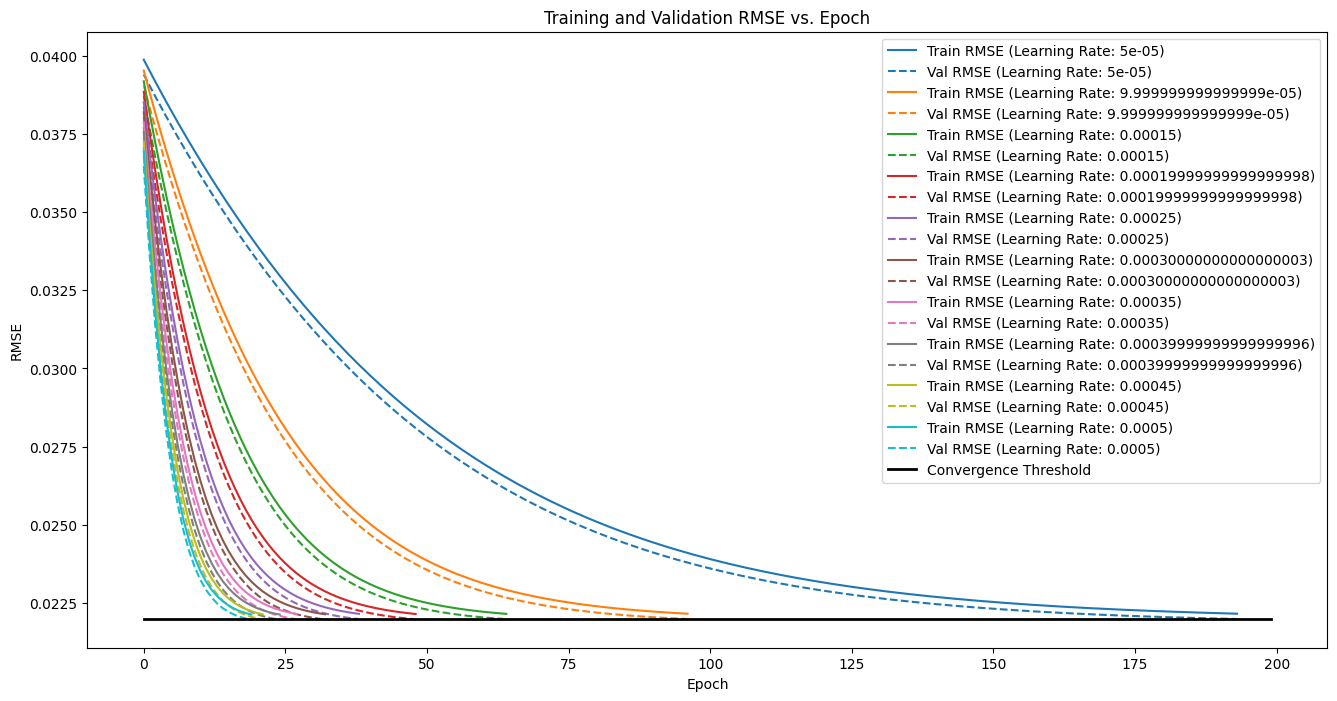

In [92]:
#plot 1: Train/Val RMSE vs Epoch for all learning rates
plt.figure(figsize=(16, 8))
colours = cm.get_cmap('tab10', len(lr_results))  #get a colourmap to make sure no colours repeat

for idx, (learning_rate, (train_rmse, val_rmse, epoch_times)) in enumerate(lr_results.items()):
  colour = colours(idx)
  plt.plot(train_rmse, label=f'Train RMSE (Learning Rate: {learning_rate})', color=colour)
  plt.plot(val_rmse, linestyle = 'dashed', label=f'Val RMSE (Learning Rate: {learning_rate})', color=colour)
plt.plot([ct]*200, linewidth=2, color='black', label="Convergence Threshold")
plt.title('Training and Validation RMSE vs. Epoch')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.show()

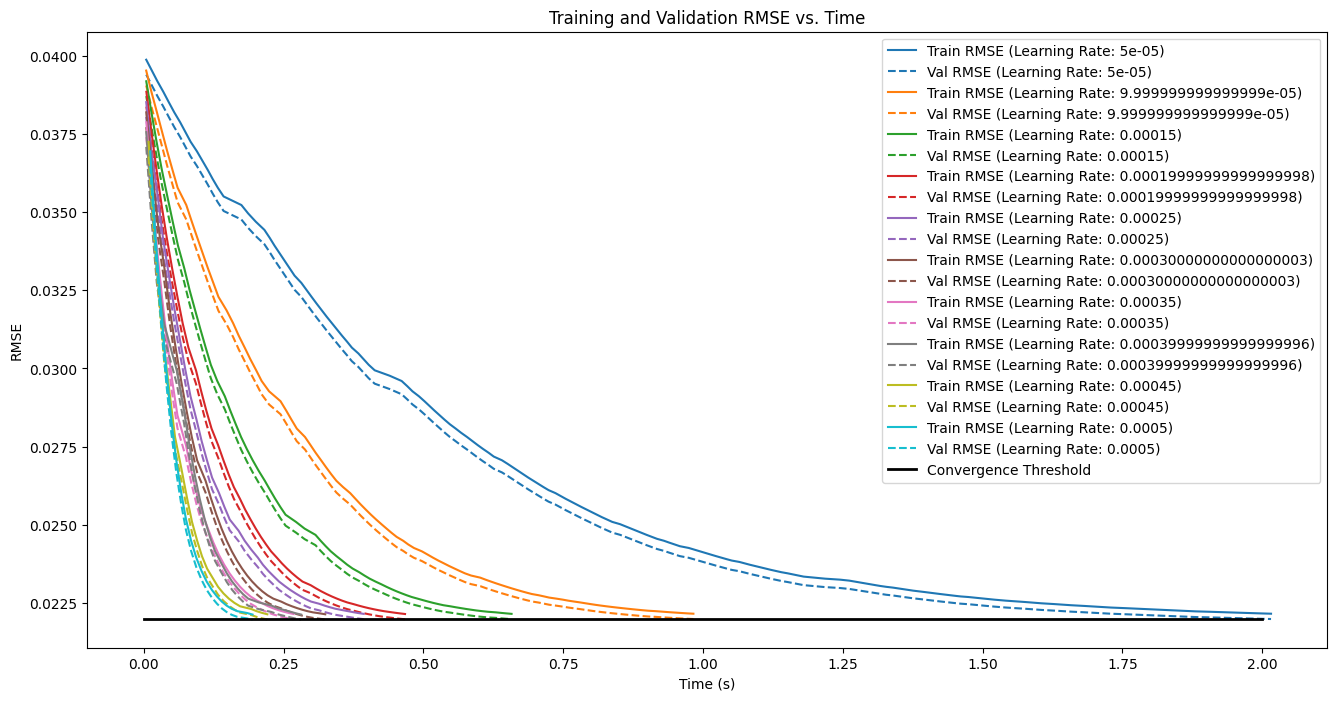

In [93]:
#plot Train/Val RMSE vs Time for converging epochs
plt.figure(figsize=(16, 8))
for idx, (learning_rate, (train_rmse, val_rmse, epoch_times)) in enumerate(lr_results.items()):
  colour = colours(idx)
  plt.plot(epoch_times, train_rmse, label=f'Train RMSE (Learning Rate: {learning_rate})', color=colour)
  plt.plot(epoch_times, val_rmse, linestyle='dashed', label=f'Val RMSE (Learning Rate: {learning_rate})',color=colour)
plt.plot([ct]*3, linewidth=2, color='black', label="Convergence Threshold")
plt.title('Training and Validation RMSE vs. Time')
plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('RMSE')
plt.show()

In [87]:
#create summary table of lr, train/val RMSE, and # of epochs
data = {'Learning Rate': [], 'Train RMSE': [], 'Val RMSE': [], '# of Epochs': []}
for lr, (train_rmse, val_rmse, epoch_times) in lr_results.items():
  data['Learning Rate'].append(lr)
  data['Train RMSE'].append(train_rmse[-1])
  data['Val RMSE'].append(val_rmse[-1])
  data['# of Epochs'].append(len(epoch_times))

summary = pd.DataFrame(data)
summary

,Learning Rate,Train RMSE,Val RMSE,# of Epochs
0,0.00005,0.022156,0.021986,194
1,0.00010,0.022156,0.021986,97
2,0.00015,0.022151,0.021982,65
3,0.00020,0.022146,0.021978,49
4,0.00025,0.022151,0.021982,39
5,0.00030,0.022137,0.021970,33
6,0.00035,0.022146,0.021978,28
7,0.00040,0.022128,0.021963,25
8,0.00045,0.022137,0.021970,22
9,0.00050,0.022129,0.021963,20


In [88]:
summary.sort_values(by=['Val RMSE'])

,Learning Rate,Train RMSE,Val RMSE,# of Epochs
7,0.00040,0.022128,0.021963,25
9,0.00050,0.022129,0.021963,20
8,0.00045,0.022137,0.021970,22
5,0.00030,0.022137,0.021970,33
3,0.00020,0.022146,0.021978,49
6,0.00035,0.022146,0.021978,28
4,0.00025,0.022151,0.021982,39
2,0.00015,0.022151,0.021982,65
1,0.00010,0.022156,0.021986,97
0,0.00005,0.022156,0.021986,194


**Findings & Main Takeaways**

---
In general, what we can take away from the plots when keeping the batch size fixed (at 32) is that both the number of epochs and time it takes to converge increases as the learning rate decreases. RMSE shows a trend of converging steadily to the threshold for all learning rates, just at different rates.

It can be observed that lower learning rates have a slower initial convergence but they tend to result in a smoother decline in RMSE without abrupt/noisy oscillations. From the summary tables above, we see that the Val RMSE slightly improves up until a learning rate of 0.0004 (achieving the minimum value of 0.021963). Beyond this the val RMSE increases, showing that higher learning rates do not significantly improve the results. Similarly, looking at the number of epochs it takes to converge at this learning rate (25) demonstrates that this is likely the optimal model for the batch size.

Both plots exhibit very similar trends, where the RMSE starts off high and gradually converges. The val RMSE follows closely to the train RMSE which indicates the model is still able to generalize well with little to no over/underfitting. For smaller learning rates beyond 0.0004, we see little improvement in RMSE despite the faster convergence. From graph 1, there as the learning rate becomes larger, the number of epochs required to converge decreases. However, there is a marginal difference in the number of epochs it takes to converge past a learning rate of 0.00035 (28 epochs) as the model still converges to about the same RMSE value. We also see that for smaller learning rates, it takes significantly more time to converge as they are less computationally efficient from the second graph. For smaller learning rates in graph 2, they are noticeably less smooth than the larger plots (which converge more quickly). This is likely attributed to the fact that smaller learning rates take smaller steps during gradient descent requiring more updates to reach convergence. As a result, this increases the likelihood of variance in the RMSE values.



In [99]:
%%shell
jupyter nbconvert --to html /content/TiffanyCostas_F24_APS1070_Project_4.ipynb

[NbConvertApp] Converting notebook /content/TiffanyCostas_F24_APS1070_Project_4.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 1535071 bytes to /content/TiffanyCostas_F24_APS1070_Project_4.html
